# Results: s4 ResNet (4.52M parameters) on CIFAR-10
This notebook checks the numbers in the report with the saved checkpoints and logs:
1. the architecture and the number of trainable parameters,
2. the held-out accuracy of the recipe (model trained on 45,000 images, tested on the other 5,000),
3. the final model: its predictions on the 2,000 hidden test images are recomputed and compared with the file we submitted, and its Kaggle test accuracy is printed,
4. training curves and all Kaggle scores.

Data: download the competition data into `data.noindex/` (see the README). The hidden test labels are not public, so the test accuracy comes from Kaggle.

In [1]:
import csv, json, os, sys
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('..'))
from train import ARCHS, ResNet, load
DEV = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print('device:', DEV)

device: mps


## 1. Architecture and parameter count

In [2]:
model = ResNet(**ARCHS['s4'])
count = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
f, i = model.features, 3
print(f"{'part':<26}{'parameters':>12}")
print(f"{'stem conv3x3 + BN':<26}{count(f[0]) + count(f[1]):>12,}")
for s, (w, n) in enumerate(zip(ARCHS['s4']['widths'], ARCHS['s4']['blocks'])):
    print(f"{f'stage {s + 1}: {n} block(s), {w} ch':<26}{sum(count(f[i + j]) for j in range(n)):>12,}")
    i += n
print(f"{'avg pool + linear':<26}{count(model.fc):>12,}")
n_params = count(model)
print(f'\nTotal trainable parameters: {n_params:,}')
assert n_params <= 5_000_000

part                        parameters
stem conv3x3 + BN                1,856
stage 1: 2 block(s), 64 ch     147,968
stage 2: 2 block(s), 128 ch     525,568
stage 3: 2 block(s), 256 ch   2,099,712
stage 4: 1 block(s), 320 ch   1,742,720
avg pool + linear                3,210

Total trainable parameters: 4,521,034


## 2. Held-out accuracy of the recipe
Recipe: s4, TrivialAugment, Cutout 16, label smoothing 0.1, SAM rho 0.05, 300 epochs, seed 0, trained on 45,000 images. The held-out set is the same 5,000 images that `train.py` keeps out (`np.random.default_rng(0)` permutation).

In [3]:
xtr, ytr, _ = load('train')
perm = np.random.default_rng(0).permutation(len(xtr))
tr, va = perm[5000:], perm[:5000]
to_t = lambda a: torch.from_numpy(a).permute(0, 3, 1, 2).contiguous().float() / 255

@torch.no_grad()
def predict(net, X, mean, std, views=10):
    """Same test-time views as train.py: image + flip, at the original position and (views=10) 4 shifts of 2 px."""
    shifts = [(0, 0)] if views == 2 else [(0, 0), (2, 0), (-2, 0), (0, 2), (0, -2)]
    out = []
    for k in range(0, len(X), 500):
        xp = F.pad(((X[k:k + 500] - mean) / std).to(DEV), (2, 2, 2, 2), mode='reflect')
        acc = 0
        for dy, dx in shifts:
            xb = xp[:, :, 2 + dy:34 + dy, 2 + dx:34 + dx]
            acc = acc + net(xb) + net(xb.flip(3))
        out.append((acc / (2 * len(shifts))).cpu())
    return torch.cat(out)

def load_model(path):
    m = ResNet(**ARCHS['s4'])
    m.load_state_dict(torch.load(path, map_location='cpu', weights_only=True))
    return m.to(DEV).eval()

Xtr45 = to_t(xtr[tr])
mean45, std45 = Xtr45.mean((0, 2, 3), keepdim=True), Xtr45.std((0, 2, 3), keepdim=True)
m45 = load_model('../checkpoints/s4_sam_seed0_train45k.pt')
Xva, Yva = to_t(xtr[va]), torch.from_numpy(ytr[va])
for v in (2, 10):
    acc = (predict(m45, Xva, mean45, std45, v).argmax(1) == Yva).float().mean().item() * 100
    print(f'Held-out accuracy, 5,000 images, {v} test views: {acc:.2f}%')

Held-out accuracy, 5,000 images, 2 test views: 97.66%


Held-out accuracy, 5,000 images, 10 test views: 97.54%


## 3. Final model and test accuracy
Final submission: same recipe, seed 2, trained on all 50,000 images. We recompute its predictions on the 2,000 hidden test images and compare them with `results/submission_final.csv`, the file that Kaggle scored.

In [4]:
Xall = to_t(xtr)
mean50, std50 = Xall.mean((0, 2, 3), keepdim=True), Xall.std((0, 2, 3), keepdim=True)
mfin = load_model('../checkpoints/s4_final_sam_seed2_full50k.pt')
print(f'Final model trainable parameters: {count(mfin):,}')
xte, _, ids = load('test')
pred = predict(mfin, to_t(xte), mean50, std50, 10).argmax(1).numpy()
sub = {int(r['id']): int(r['label']) for r in csv.DictReader(open('../results/submission_final.csv'))}
same = np.mean([pred[k] == sub[int(i)] for k, i in enumerate(ids)])
print(f'Recomputed predictions match the submitted file on {same * 100:.2f}% of {len(ids):,} hidden images')
rows = list(csv.DictReader(open('../results/kaggle_submissions.csv')))
final = [r for r in rows if r['description'].startswith('v5: s4 4.52M + TA + SAM rho 0.05, 300 ep, full 50k, seed 2')][0]
pub, pri = float(final['publicScore']) * 100, float(final['privateScore']) * 100
print(f'Kaggle test accuracy of the final model: public {pub:.1f}%, private {pri:.1f}%, all 2,000 images {(pub + pri) / 2:.2f}%')

Final model trainable parameters: 4,521,034


Recomputed predictions match the submitted file on 100.00% of 2,000 hidden images
Kaggle test accuracy of the final model: public 89.3%, private 85.6%, all 2,000 images 87.45%


## 4. Training curves (held-out split, 45,000 training images)

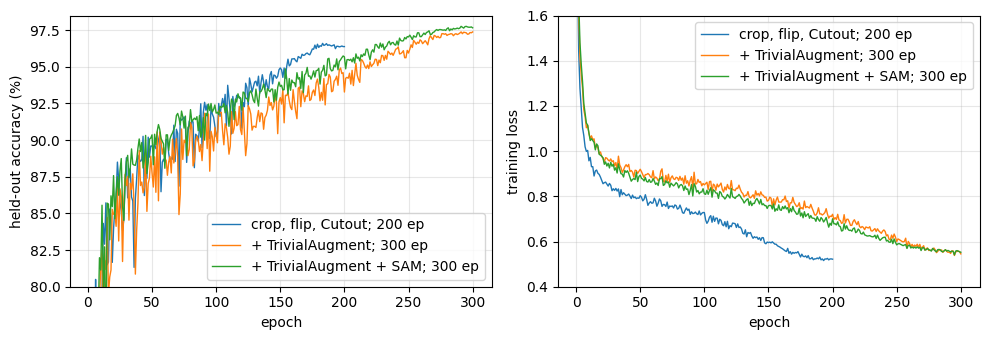

In [5]:
runs = [('s4_e200_s0', 'crop, flip, Cutout; 200 ep'), ('s4_ta_e300_s0', '+ TrivialAugment; 300 ep'),
        ('s4_ta_sam0.05_e300_s0', '+ TrivialAugment + SAM; 300 ep')]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for name, label in runs:
    h = json.load(open(f'../logs/runs/{name}.json'))['history']
    e = [x['epoch'] for x in h]
    ax[0].plot(e, [100 * x['val_acc'] for x in h], lw=1, label=label)
    ax[1].plot(e, [x['train_loss'] for x in h], lw=1, label=label)
ax[0].set(xlabel='epoch', ylabel='held-out accuracy (%)', ylim=(80, 98.5)); ax[1].set(xlabel='epoch', ylabel='training loss', ylim=(0.4, 1.6))
for a in ax: a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

## 5. All Kaggle submissions (public and private halves, 1,000 images each)

 public  private  description
   87.7     85.3  s4 ResNet 4.52M, 200 ep, full 50k
   87.7     84.9  v2: s4 4.52M + TrivialAugment, 300 ep, 45k train (val 97.38%)
   89.1     84.9  v2b: s4 4.52M + TrivialAugment, 300 ep, full 50k, 10-view TTA
   89.0     86.2  v3: s4 4.52M KD from r18w+2xs4 ensemble, TA, 300 ep, full 50k, 10-view TTA
   88.3     85.7  
   89.0     86.3  v5: s4 4.52M + TA + SAM rho 0.05, 300 ep, full 50k, seed 1, 10-view TTA
   89.3     85.6  v5: s4 4.52M + TA + SAM rho 0.05, 300 ep, full 50k, seed 2, 10-view TTA
   88.9     85.8  v7: s4 4.52M + TA + SAM rho 0.05, 600 ep, full 50k, seed 3, 10-view TTA
   89.2     86.6  v7: s4 4.52M + TA + SAM rho 0.05, 600 ep, full 50k, seed 4, 10-view TTA
   88.2     84.8  v9: s4hr (s4 params 4.52M, stage 3 at 16x16) + TA + SAM rho 0.05, 200 ep, full 50k, 10-vie
   89.3     85.6  v5 seed 2 (s4 + TA + SAM rho 0.05, 300 ep, full 50k) as submission.csv
   89.2     86.6  v7 seed 4 (s4 + TA + SAM rho 0.05, 600 ep, full 50k) as submission.csv

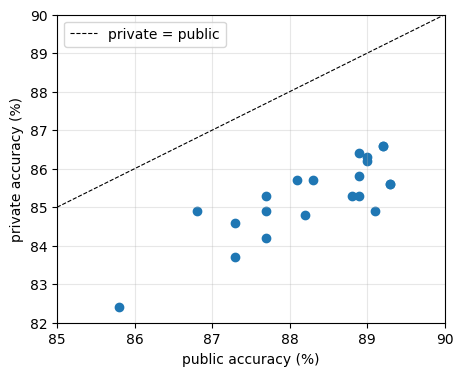

In [6]:
print(f"{'public':>7}{'private':>9}  description")
for r in rows[::-1]:
    print(f"{float(r['publicScore']) * 100:7.1f}{float(r['privateScore']) * 100:9.1f}  {r['description'][:90]}")
p = np.array([float(r['publicScore']) for r in rows]) * 100
q = np.array([float(r['privateScore']) for r in rows]) * 100
plt.figure(figsize=(5, 4)); plt.scatter(p, q); plt.plot([82, 91], [82, 91], 'k--', lw=0.8, label='private = public')
plt.xlim(85, 90); plt.ylim(82, 90); plt.xlabel('public accuracy (%)'); plt.ylabel('private accuracy (%)'); plt.legend(); plt.grid(alpha=0.3); plt.show()